# Using the dispatch.particles Python package

## Setup

In [ ]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import sys
import os

*Set this to your DISPATCH top:*

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'

Making sure to use the most current DISPATCH version:

In [4]:
sys.path.insert(0,top+'utilities/python')
cwd=top+'experiments/dust/ISM/python'
os.chdir(cwd)

In [5]:
import dispatch
import dispatch.particles

## Reading data from a ``1pc.nml`` input file run

In [6]:
p=dispatch.particles.open('../data/1pc/rank_00000.pdat',verbose=1);

 5.48 Mp -> 1.47 Mp/s   88 snapshots 21255 particles


Check that gas density is present in all bins:

In [7]:
for bin in range(3):
    w=np.where(p.dg[0,:,bin]==0.0)[0]
    n=len(w)
    if n>0:
        i=w[0]
        print(i,p.dg[0,i,:])

### Selecting particles with z in a narrow interval

In [8]:
bin=1
dz=0.001
w1=np.where(p.t[bin,:,1]>0.0)[0]
z0=p.r[bin,w1,2,0]
w2=np.where(abs(z0)< dz)[0]
w=w1[w2]
print('there are',len(w1),'slots filled out of',p.t.shape[1])
print('there are',len(w2),'particles in the given z-interval')

there are 20928 slots filled out of 20928
there are 64 particles in the given z-interval


#### Plotting their starting points

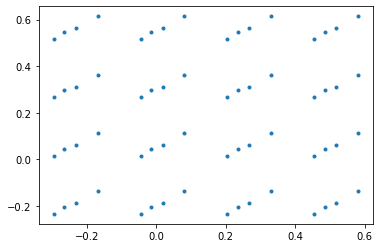

In [9]:
x0=p.r[bin,w,0,0]
y0=p.r[bin,w,1,0]
pl.plot(x0,y0,'.');

#### Plotting their parths in time

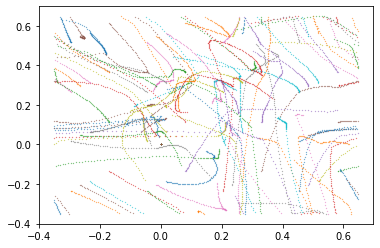

In [10]:
for i in range(len(w)):
    x=p.r[bin,w[i],0,:]
    y=p.r[bin,w[i],1,:]
    pl.plot(x,y,'.',ms=0.5)

#### Plotting paths with one color per bin and marked starting points

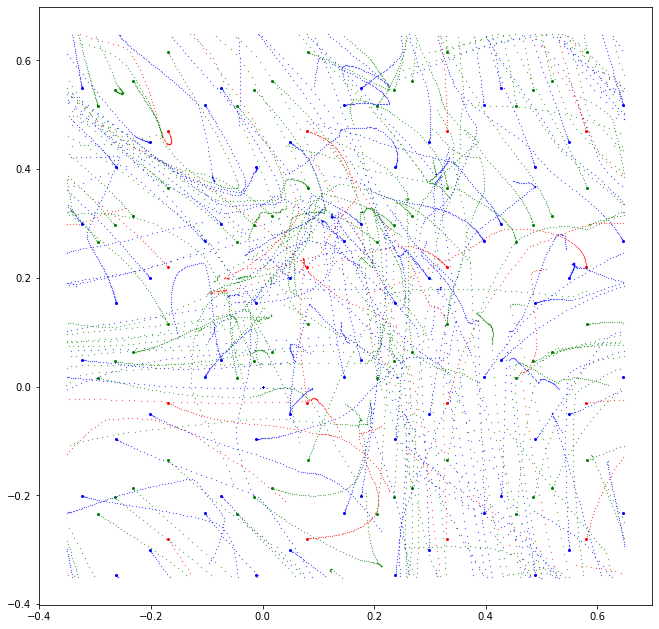

In [11]:
pl.figure(1,figsize=(11,11))
c=['r','g','b']
for bin in range(3):
    z0=p.r[bin,:,2,0]
    w=np.where(abs(z0)< dz)[0]
    for i in range(len(w)):
        x=p.r[bin,w[i],0]
        y=p.r[bin,w[i],1]
        pl.plot(x[0],y[0],'.',c=c[bin],ms=4)
        pl.plot(x,y,'.',c=c[bin],ms=0.5)